In [31]:
import pandas as pd
import numpy as np
from typing import Literal
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt

In [34]:
df = pd.read_csv("../generated_data/big_five_evaluation_results_cleaned.csv")
df

,Gender,Enthusiasm,Assertiveness,Compassion,Politeness,Industriousness,Orderliness,Volatility,Withdrawal,Intellect,...,Openness_2,Openness_3_R,Openness_4_R,Intellect_1,Intellect_2_R,Intellect_3,Intellect_4_R,llm,persona,thinking
0,male,2.31,3.65,3.33,3.39,3.76,4.75,3.14,2.97,3.92,...,5,2,1,5,1.0,4,1,deepseek-v4-pro,description,enabled
1,male,2.86,2.94,3.28,3.29,2.91,3.74,3.28,3.17,3.70,...,2,4,5,5,1.0,5,1,deepseek-v4-pro,description,enabled
2,male,3.78,2.45,4.12,2.89,2.06,3.49,2.64,3.08,3.62,...,2,5,4,5,1.0,4,1,deepseek-v4-pro,description,enabled
3,male,2.86,2.64,4.16,3.49,2.53,2.99,2.44,3.11,3.09,...,5,1,1,3,2.0,2,2,deepseek-v4-pro,description,enabled
4,male,3.53,4.20,4.14,2.00,3.17,3.36,3.07,3.44,3.50,...,5,1,1,5,1.0,4,1,deepseek-v4-pro,description,enabled
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3595,female,3.69,2.86,3.54,3.16,2.69,2.52,2.90,2.54,3.88,...,5,1,1,5,3.0,5,1,deepseek-v4-flash,no_persona,disabled
3596,female,3.31,2.18,3.66,3.07,2.82,2.84,2.93,2.63,2.46,...,5,5,1,5,3.0,5,5,deepseek-v4-flash,no_persona,disabled
3597,female,2.38,4.42,3.16,2.43,2.20,1.27,2.29,2.41,3.92,...,5,1,3,5,5.0,5,3,deepseek-v4-flash,no_persona,disabled
3598,female,3.89,3.72,2.98,1.65,2.31,2.63,3.02,4.26,2.21,...,5,4,4,5,3.0,5,2,deepseek-v4-flash,no_persona,disabled


In [36]:
df.loc[2454, "Enthusiasm_4_R"]

'"\n\nThen the user prompt continues with: "You will be provided with a phrase describing people\'s behaviors. \nDescribe yourself as you generally are now, not as you wish to be in the future.\nDescribe yourself as you honestly see yourself, in relation to other people you know of the same sex as you are.\n\nRate the following statement on a scale from 1 to 5, where:\n1 - Very Inaccurate\n2 - Moderately Inaccurate\n3 - Neither Accurate, Nor Inaccurate\n4 - Moderately Accurate\n5 - Very Accurate\n\nYour entire response must consist of exactly one digit: 1, 2, 3, 4, or 5.\n-------------------------------------\nStatement:\nam not a very enthusiastic person"\n\nSo it seems like the "phrase describing people\'s behaviors" might be the statement itself, or maybe it\'s missing. Possibly, the task is to simulate a person with a particular trait, and the trait is given by the phrase? But the phrase is "am not a very enthusiastic person", which is a self-description. Maybe the simulation is: y

In [33]:
subfacette_item_cols = [col for col in df.columns if "_" in col and col not in ["Openness_Intellect", "experiment_group"]]

df = df.dropna(axis=0).copy()

for item in subfacette_item_cols:
    df[item] = pd.to_numeric(df[item], errors="coerce")
    invalid_mask = ~df[item].isin([1, 2, 3, 4, 5])

    if invalid_mask.any():
        print(df.loc[invalid_mask, ["llm", "persona", "thinking", item]])
        print("--------------------")

    df = df.loc[~invalid_mask].copy()
    df[item] = df[item].astype("Int64")

                  llm     persona  thinking  Politeness_1_R
3013  deepseek-v4-pro  no_persona  disabled               6
--------------------
                  llm     persona thinking  Enthusiasm_4_R
2454  deepseek-v4-pro  no_persona  enabled             NaN
--------------------
                  llm      persona  thinking  Openness_1
1303  deepseek-v4-pro  raw_persona   enabled         0.4
3273  deepseek-v4-pro   no_persona  disabled         7.0
--------------------


In [5]:
# invert reverse coded items
reverse_cols = [col for col in df.columns if col.endswith("_R")]
df[reverse_cols] = 6 - df[reverse_cols]
df

,Gender,Enthusiasm,Assertiveness,Compassion,Politeness,Industriousness,Orderliness,Volatility,Withdrawal,Intellect,...,Openness_2,Openness_3_R,Openness_4_R,Intellect_1,Intellect_2_R,Intellect_3,Intellect_4_R,llm,persona,thinking
0,male,2.31,3.65,3.33,3.39,3.76,4.75,3.14,2.97,3.92,...,5,4,5,5,5,4,5,deepseek-v4-pro,description,enabled
1,male,2.86,2.94,3.28,3.29,2.91,3.74,3.28,3.17,3.70,...,2,2,1,5,5,5,5,deepseek-v4-pro,description,enabled
2,male,3.78,2.45,4.12,2.89,2.06,3.49,2.64,3.08,3.62,...,2,1,2,5,5,4,5,deepseek-v4-pro,description,enabled
3,male,2.86,2.64,4.16,3.49,2.53,2.99,2.44,3.11,3.09,...,5,5,5,3,4,2,4,deepseek-v4-pro,description,enabled
4,male,3.53,4.20,4.14,2.00,3.17,3.36,3.07,3.44,3.50,...,5,5,5,5,5,4,5,deepseek-v4-pro,description,enabled
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3595,female,3.69,2.86,3.54,3.16,2.69,2.52,2.90,2.54,3.88,...,5,5,5,5,3,5,5,deepseek-v4-flash,no_persona,disabled
3596,female,3.31,2.18,3.66,3.07,2.82,2.84,2.93,2.63,2.46,...,5,1,5,5,3,5,1,deepseek-v4-flash,no_persona,disabled
3597,female,2.38,4.42,3.16,2.43,2.20,1.27,2.29,2.41,3.92,...,5,5,3,5,1,5,3,deepseek-v4-flash,no_persona,disabled
3598,female,3.89,3.72,2.98,1.65,2.31,2.63,3.02,4.26,2.21,...,5,2,2,5,3,5,4,deepseek-v4-flash,no_persona,disabled


In [6]:
def get_traits(type: Literal["Big_Five", "Subdomain"]):
    """Return Big Five traits or subdomains."""
    
    big_five = {
        "Extraversion": ["Enthusiasm", "Assertiveness"],
        "Agreeableness": ["Compassion", "Politeness"],
        "Conscientiousness": ["Industriousness", "Orderliness"],
        "Neuroticism": ["Volatility", "Withdrawal"],
        "Openness_Intellect": ["Intellect", "Openness"],
    }

    if type == "Big_Five":
        return big_five

    return [subfacet for subfacets in big_five.values() for subfacet in subfacets]

In [7]:
subdomains = get_traits("Subdomain")
for subdomain in subdomains:
    subfacete_items = [col for col in df.columns if col.startswith(f"{subdomain}_") and not col.endswith("_Intellect")]
    df[f"{subdomain}_evaluated"] = df[subfacete_items].mean(axis=1)

big_five = get_traits("Big_Five")
for trait, subfacets in big_five.items():
    subfacet_cols = [f"{subfacet}_evaluated" for subfacet in subfacets]
    df[f"{trait}_evaluated"] = df[subfacet_cols].mean(axis=1)
df

,Gender,Enthusiasm,Assertiveness,Compassion,Politeness,Industriousness,Orderliness,Volatility,Withdrawal,Intellect,...,Orderliness_evaluated,Volatility_evaluated,Withdrawal_evaluated,Intellect_evaluated,Openness_evaluated,Extraversion_evaluated,Agreeableness_evaluated,Conscientiousness_evaluated,Neuroticism_evaluated,Openness_Intellect_evaluated
0,male,2.31,3.65,3.33,3.39,3.76,4.75,3.14,2.97,3.92,...,5.0,2.5,2.0,4.75,4.75,2.875,3.25,5.0,2.25,4.75
1,male,2.86,2.94,3.28,3.29,2.91,3.74,3.28,3.17,3.70,...,4.75,3.0,2.5,5.0,2.5,2.125,4.125,3.75,2.75,3.75
2,male,3.78,2.45,4.12,2.89,2.06,3.49,2.64,3.08,3.62,...,4.25,1.75,1.75,4.75,2.25,3.125,4.875,2.75,1.75,3.5
3,male,2.86,2.64,4.16,3.49,2.53,2.99,2.44,3.11,3.09,...,2.0,1.25,4.25,3.25,5.0,1.625,5.0,2.125,2.75,4.125
4,male,3.53,4.20,4.14,2.00,3.17,3.36,3.07,3.44,3.50,...,3.5,4.5,3.5,4.75,5.0,4.875,3.625,2.625,4.0,4.875
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3595,female,3.69,2.86,3.54,3.16,2.69,2.52,2.90,2.54,3.88,...,4.25,4.0,2.75,4.5,5.0,3.375,3.5,3.125,3.375,4.75
3596,female,3.31,2.18,3.66,3.07,2.82,2.84,2.93,2.63,2.46,...,3.75,3.5,3.0,3.5,4.0,3.25,3.625,2.625,3.25,3.75
3597,female,2.38,4.42,3.16,2.43,2.20,1.27,2.29,2.41,3.92,...,3.75,3.5,2.75,3.5,4.5,3.5,3.375,3.125,3.125,4.0
3598,female,3.89,3.72,2.98,1.65,2.31,2.63,3.02,4.26,2.21,...,4.0,4.25,2.75,4.25,3.25,3.125,3.0,3.0,3.5,3.75


In [8]:
evaluation_results = []
subfacets = get_traits("Subdomain")
for (llm, persona, thinking), condition in df.groupby(["llm", "persona", "thinking"]):
    
    for trait in subfacets:

        # assigned values
        y = condition[trait]
        # predicted values by the LLM
        y_pred = condition[f"{trait}_evaluated"]

        pearson_r, pearson_p = pearsonr(y, y_pred)
        spearman_rho, spearman_p = spearmanr(y, y_pred)
        
        evaluation_results.append({
            "llm": llm,
            "persona": persona,
            "thinking": thinking,
            "trait": trait,
            "N": len(y),
            "pearson_r": pearson_r,
            "pearson_p": pearson_p,
            "spearman_rho": spearman_rho,
            "spearman_p": spearman_p,
            "R²": r2_score(y, y_pred),
            "MAE": mean_absolute_error(y, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y, y_pred))
        })
evaluation_df = pd.DataFrame(evaluation_results)
evaluation_df["pearson_p_adjusted"] = (evaluation_df["pearson_p"] * len(evaluation_df)).clip(upper=1)
evaluation_df["spearman_p_adjusted"] = (evaluation_df["spearman_p"] * len(evaluation_df)).clip(upper=1)

evaluation_df.round(3)

,llm,persona,thinking,trait,N,pearson_r,pearson_p,spearman_rho,spearman_p,R²,MAE,RMSE,pearson_p_adjusted,spearman_p_adjusted
0,deepseek-v4-flash,description,disabled,Enthusiasm,300,0.464,0.000,0.499,0.000,-1.087,0.782,0.957,0.0,0.0
1,deepseek-v4-flash,description,disabled,Assertiveness,300,0.640,0.000,0.638,0.000,0.346,0.414,0.533,0.0,0.0
2,deepseek-v4-flash,description,disabled,Compassion,300,0.565,0.000,0.523,0.000,0.147,0.443,0.541,0.0,0.0
3,deepseek-v4-flash,description,disabled,Politeness,300,0.075,0.197,0.069,0.231,-1.625,0.812,0.987,1.0,1.0
4,deepseek-v4-flash,description,disabled,Industriousness,300,-0.043,0.462,-0.082,0.156,-3.571,1.297,1.503,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,deepseek-v4-pro,raw_persona,enabled,Orderliness,299,0.958,0.000,0.972,0.000,0.579,0.345,0.401,0.0,0.0
116,deepseek-v4-pro,raw_persona,enabled,Volatility,299,0.947,0.000,0.965,0.000,0.696,0.346,0.415,0.0,0.0
117,deepseek-v4-pro,raw_persona,enabled,Withdrawal,299,0.957,0.000,0.961,0.000,0.568,0.397,0.466,0.0,0.0
118,deepseek-v4-pro,raw_persona,enabled,Intellect,299,0.917,0.000,0.936,0.000,0.200,0.497,0.556,0.0,0.0


In [9]:
evaluation_results = []

for (llm, persona, thinking), condition in evaluation_df.groupby(["llm", "persona", "thinking"]):
    r_mean = condition["pearson_r"].mean()
    spearman_mean = condition["spearman_rho"].mean()
    r_2_mean = condition["R²"].mean()
    MAE_mean = condition["MAE"].mean()
    RMSE_mean = condition["RMSE"].mean()

    evaluation_results.append({
        "llm": llm,
        "persona": persona,
        "thinking": thinking,
        "N": condition["N"].iloc[0],
        "pearson_r_mean": r_mean,
        "spearman_rho_mean": spearman_mean,
        "R²_mean": r_2_mean,
        "MAE_mean": MAE_mean,
        "RMSE_mean": RMSE_mean
    })

evaluation_summary_df = pd.DataFrame(evaluation_results)
evaluation_summary_df.round(3)
    

,llm,persona,thinking,N,pearson_r_mean,spearman_rho_mean,R²_mean,MAE_mean,RMSE_mean
0,deepseek-v4-flash,description,disabled,300,0.315,0.288,-0.712,0.667,0.820
1,deepseek-v4-flash,description,enabled,298,0.798,0.823,-1.390,0.890,0.997
2,deepseek-v4-flash,no_persona,disabled,300,-0.002,-0.004,-1.552,0.842,1.012
3,deepseek-v4-flash,no_persona,enabled,300,0.024,0.018,-1.626,0.866,1.042
4,deepseek-v4-flash,raw_persona,disabled,300,0.412,0.356,-0.103,0.521,0.660
5,deepseek-v4-flash,raw_persona,enabled,298,0.933,0.947,0.350,0.451,0.513
6,deepseek-v4-pro,description,disabled,299,0.466,0.466,-0.148,0.539,0.672
7,deepseek-v4-pro,description,enabled,299,0.816,0.840,-1.191,0.850,0.953
8,deepseek-v4-pro,no_persona,disabled,298,0.017,0.022,-1.492,0.821,1.004
9,deepseek-v4-pro,no_persona,enabled,299,-0.014,-0.015,-0.329,0.602,0.747


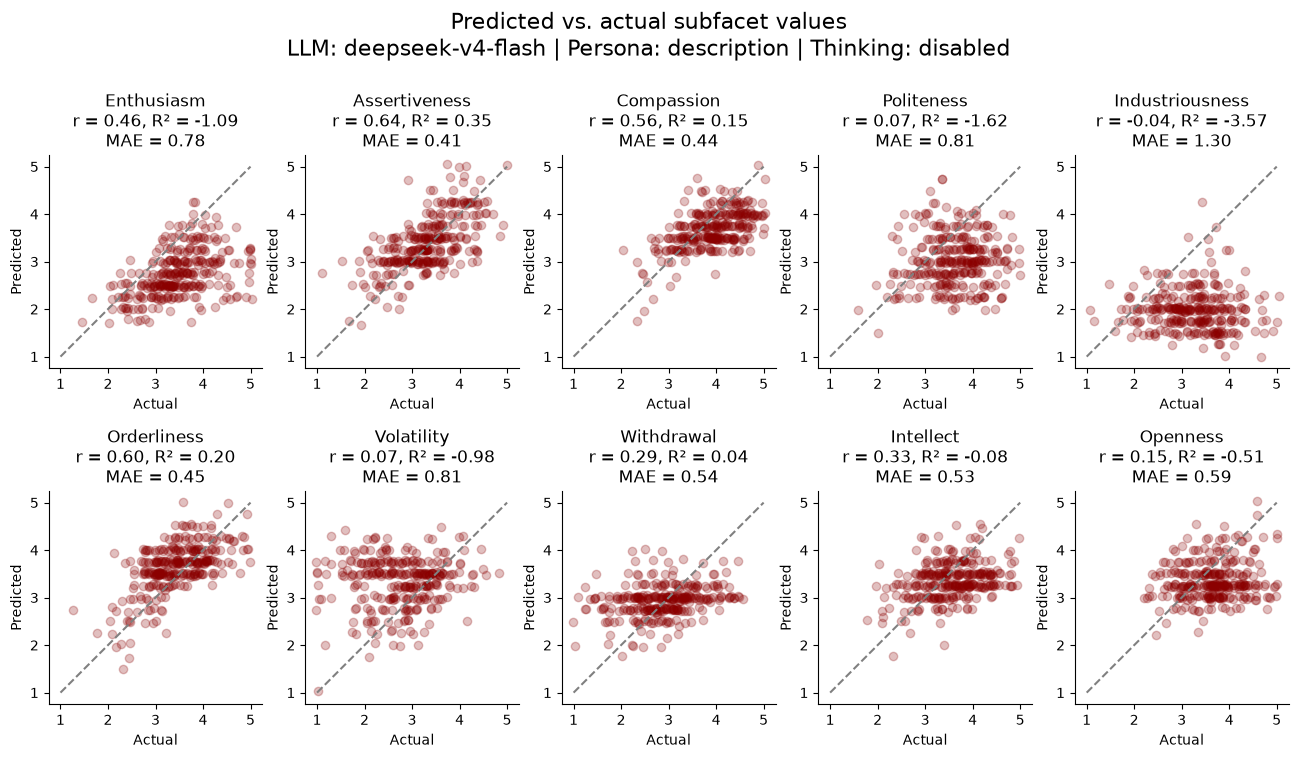

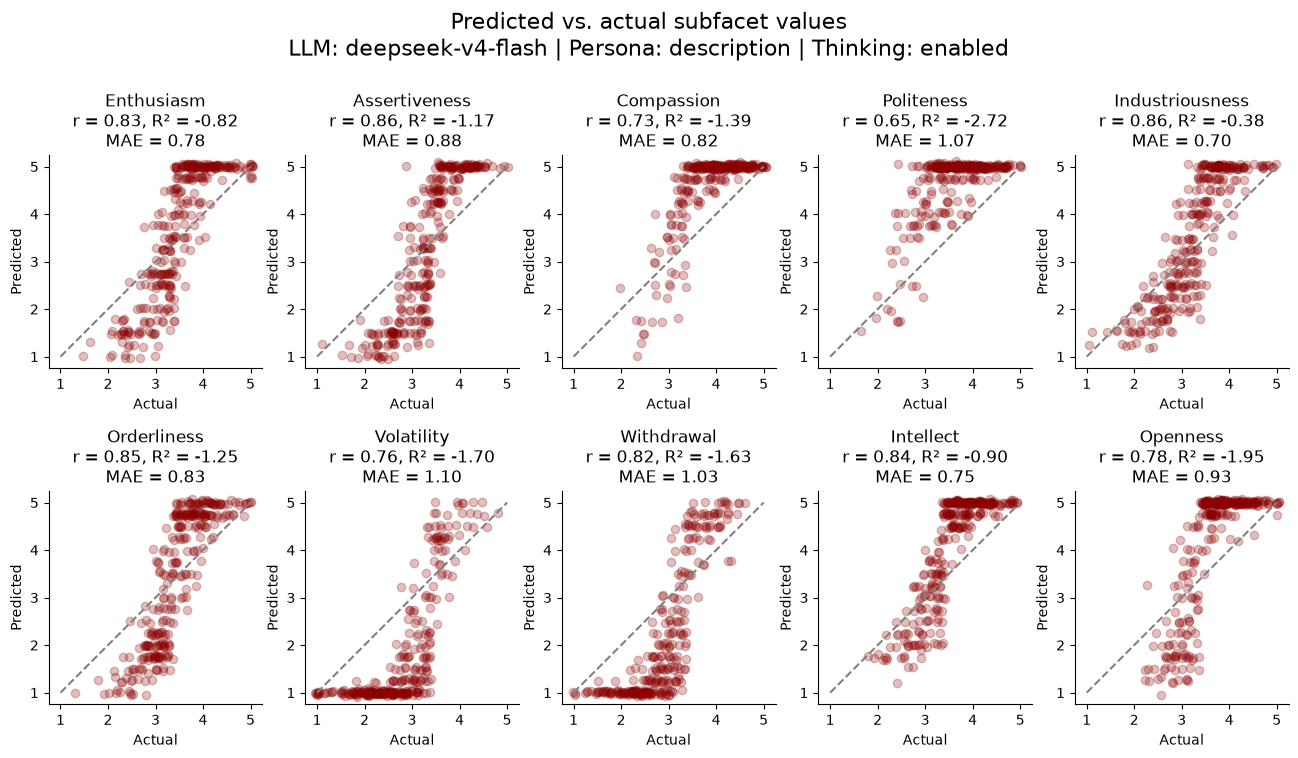

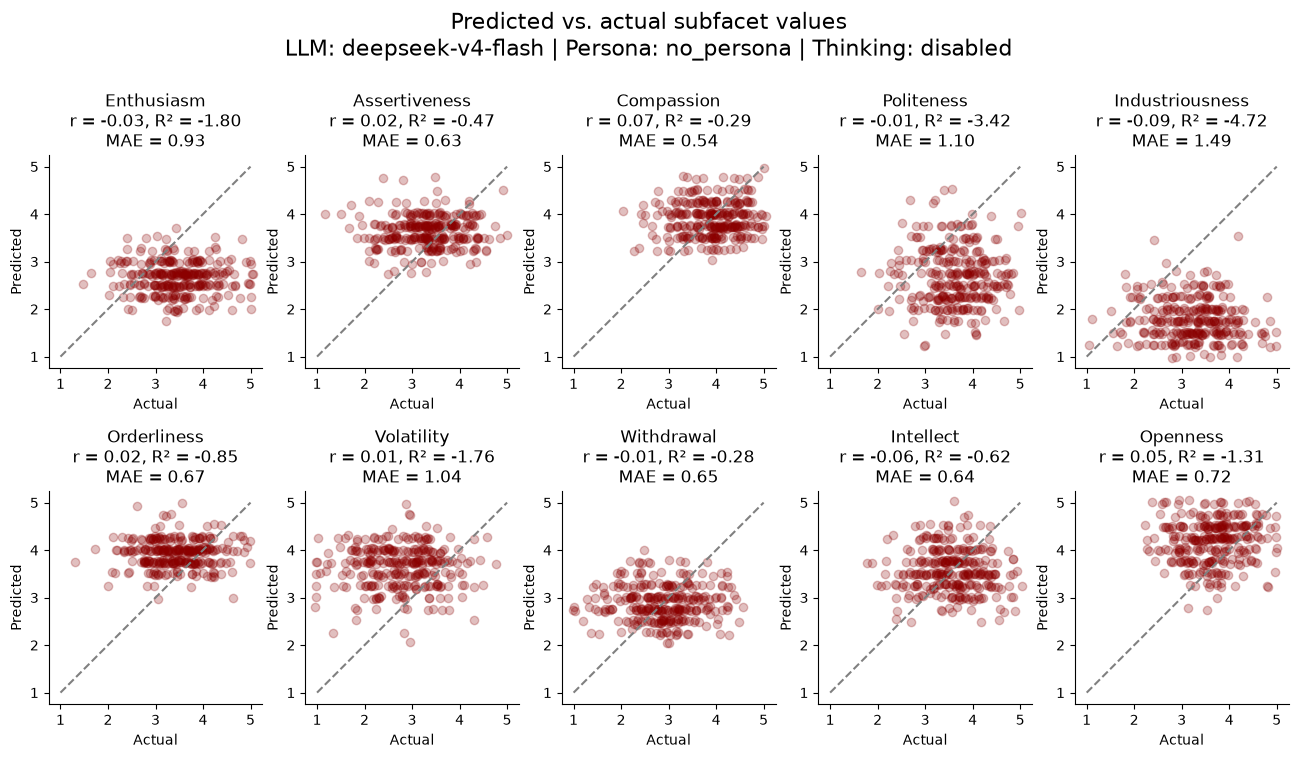

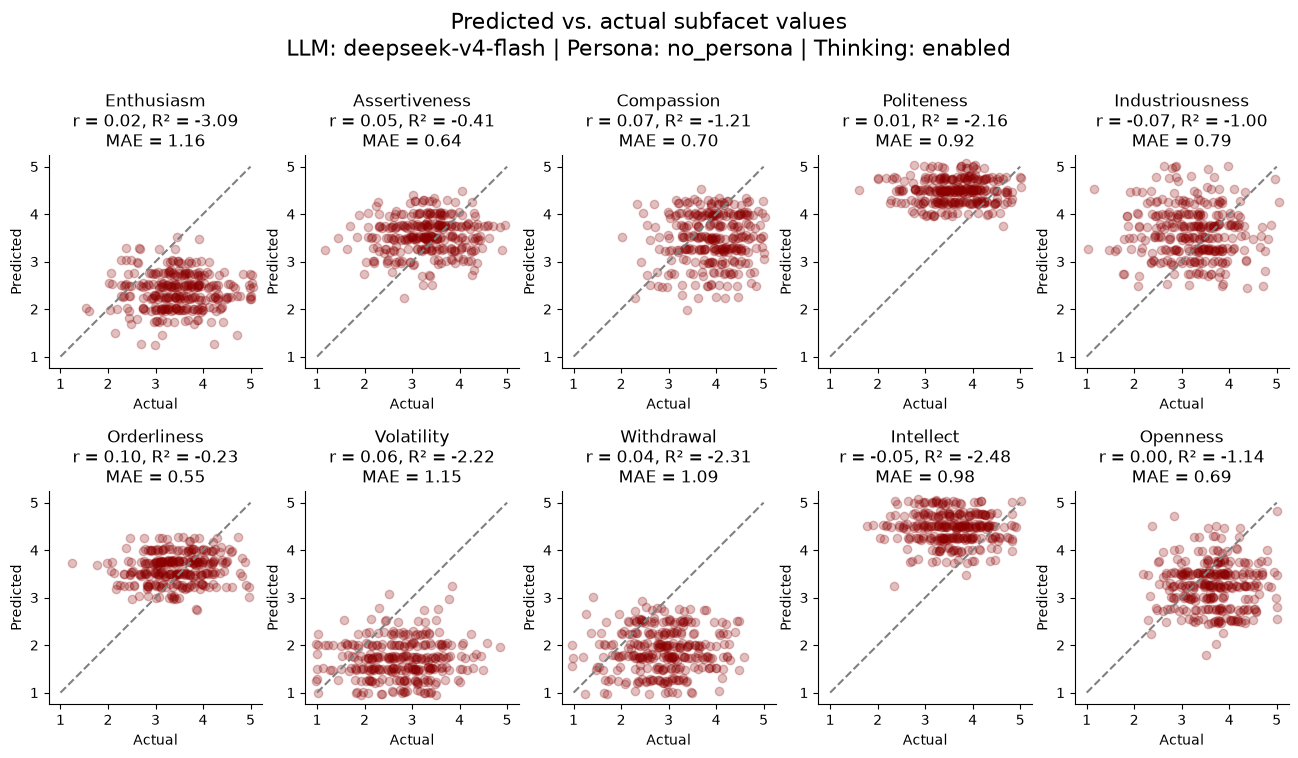

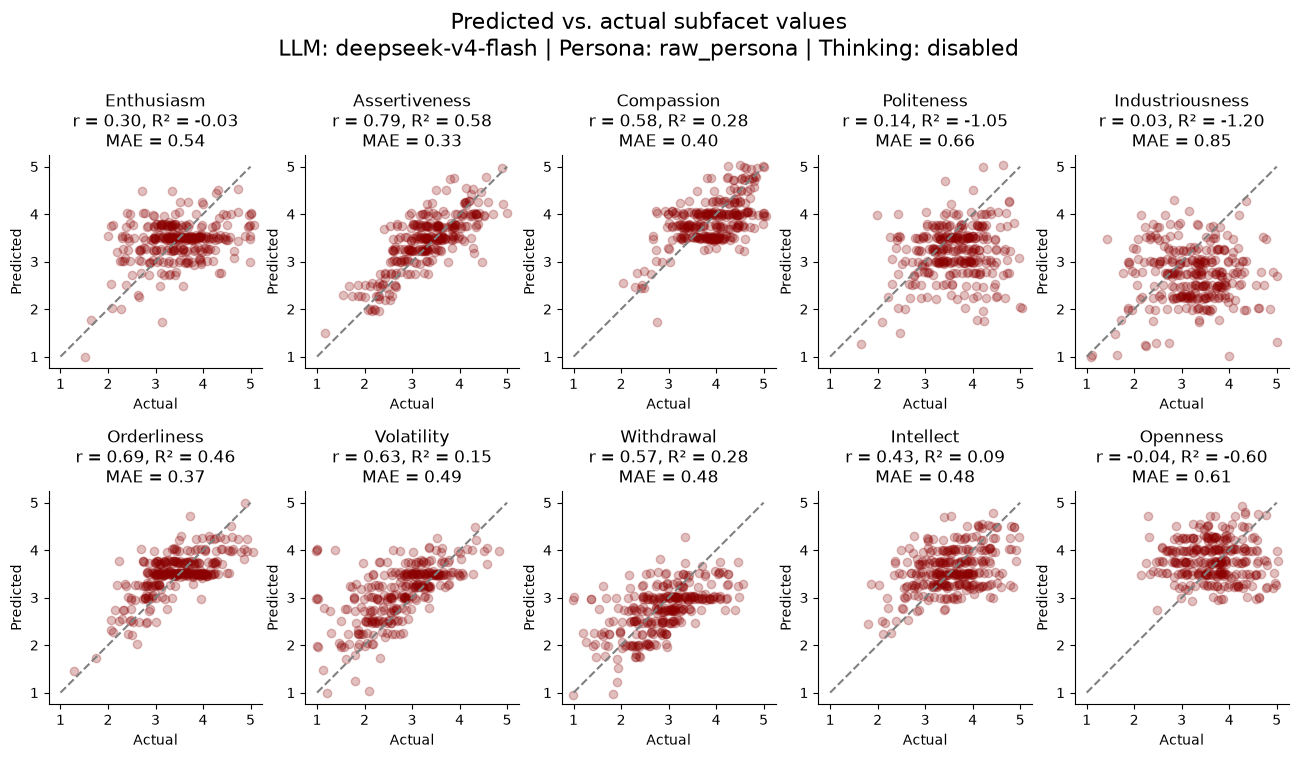

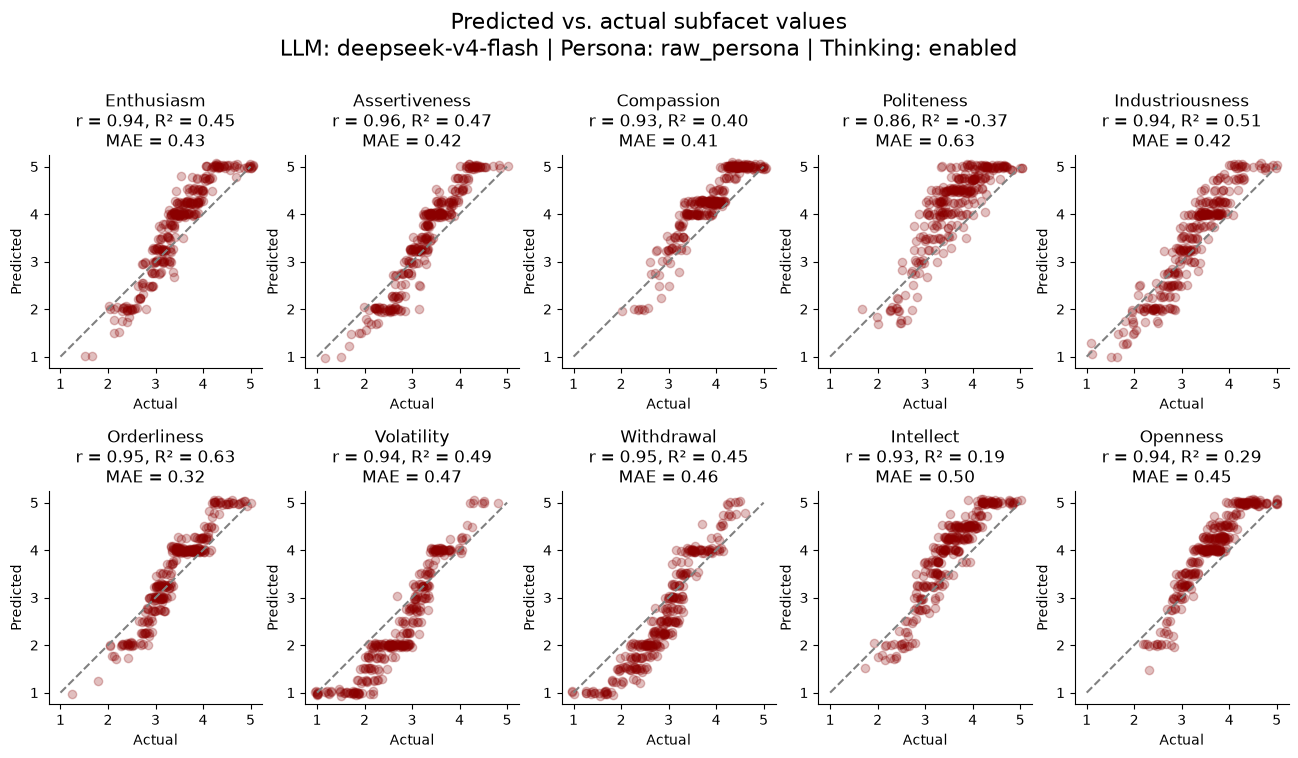

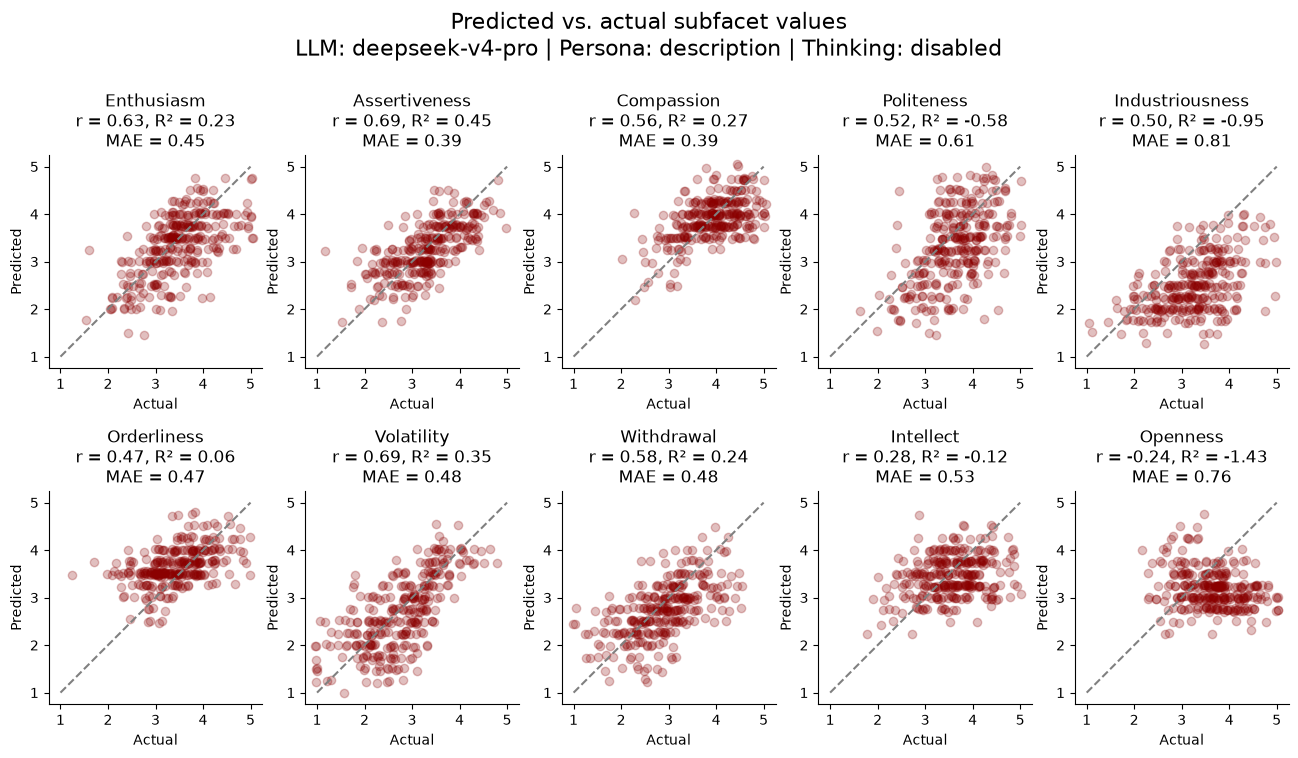

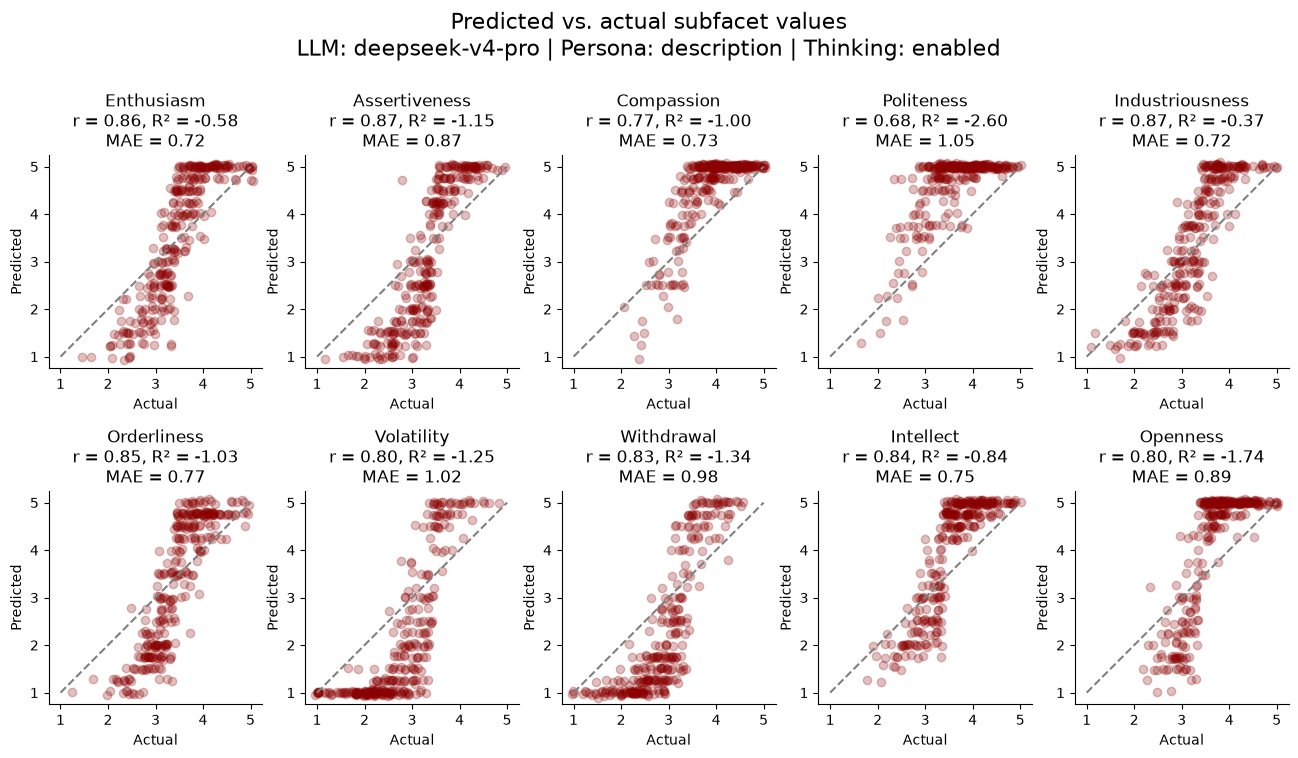

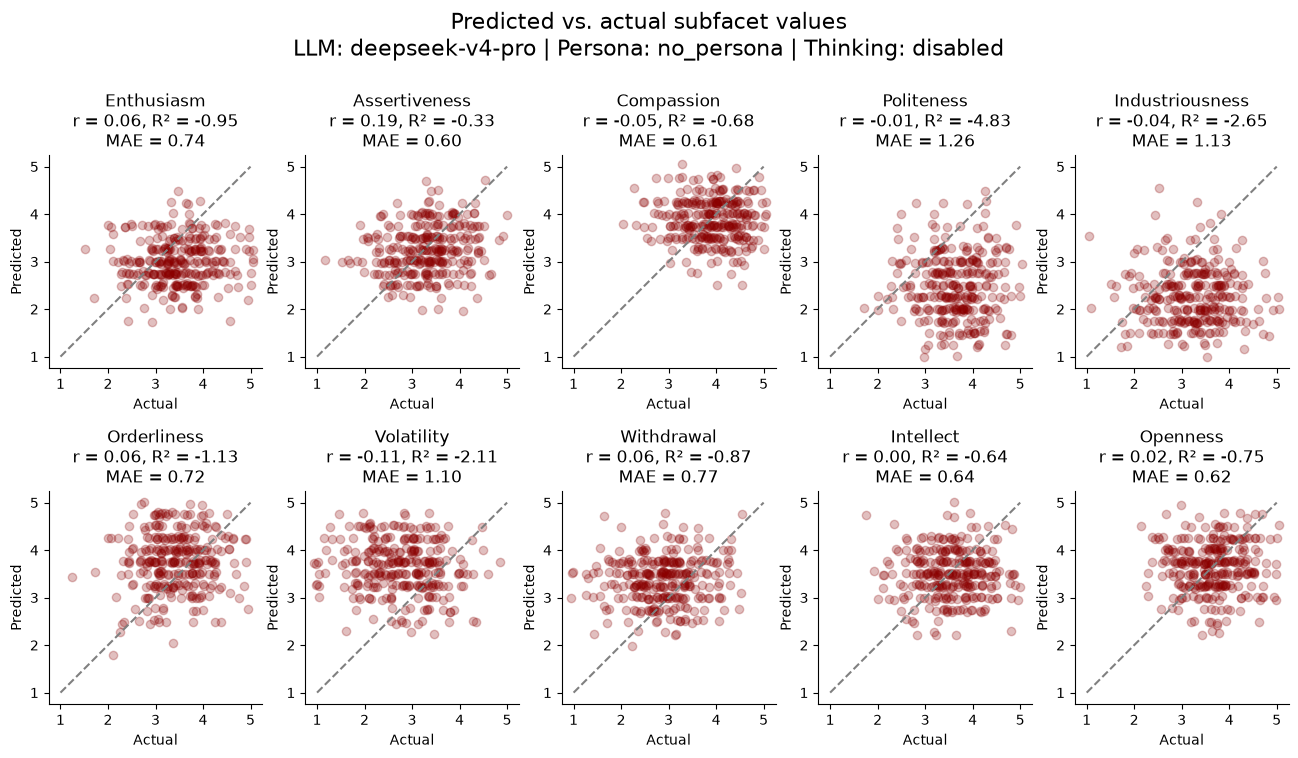

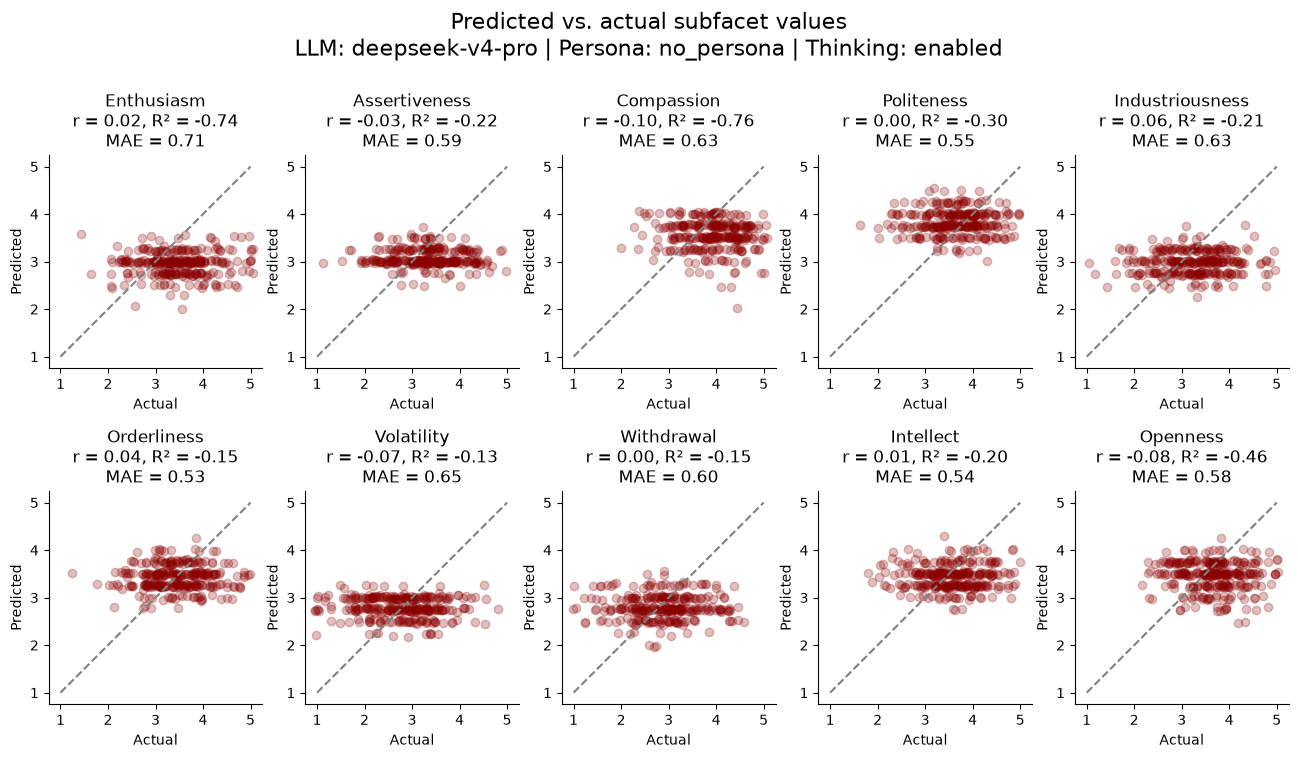

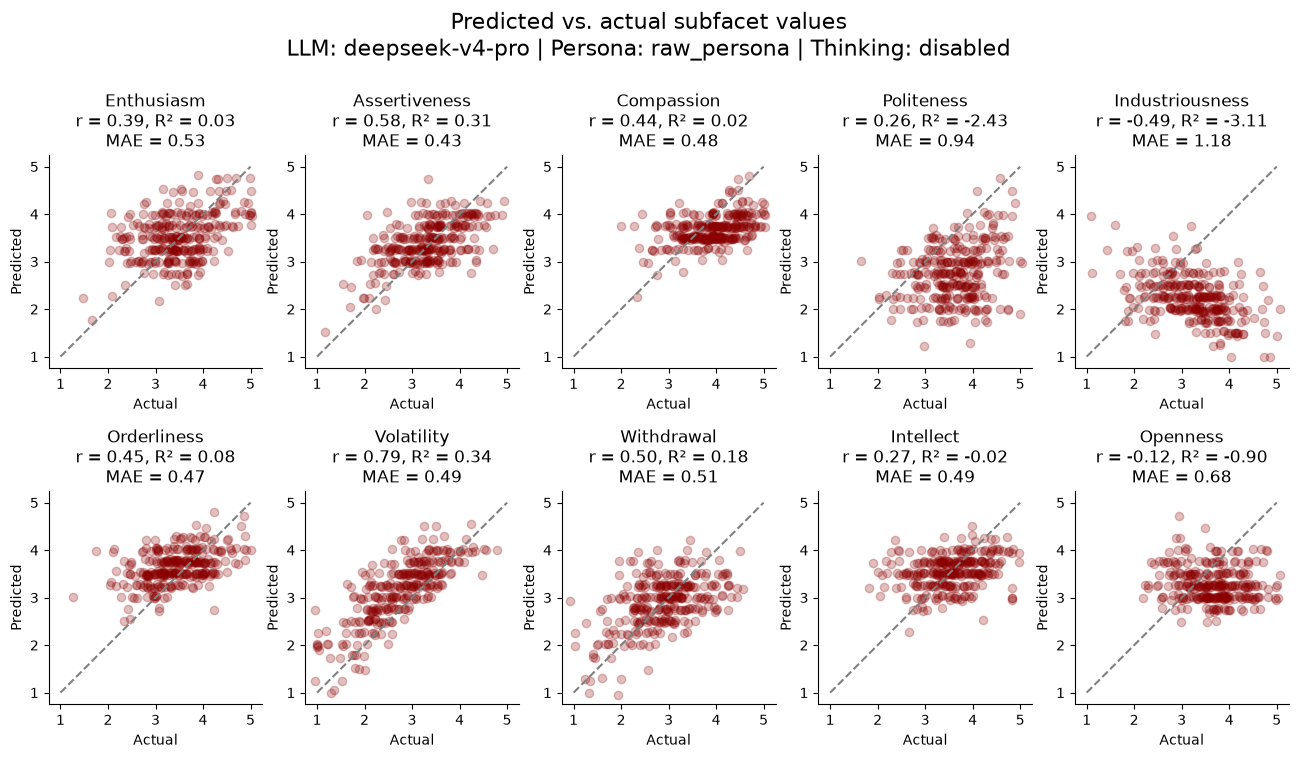

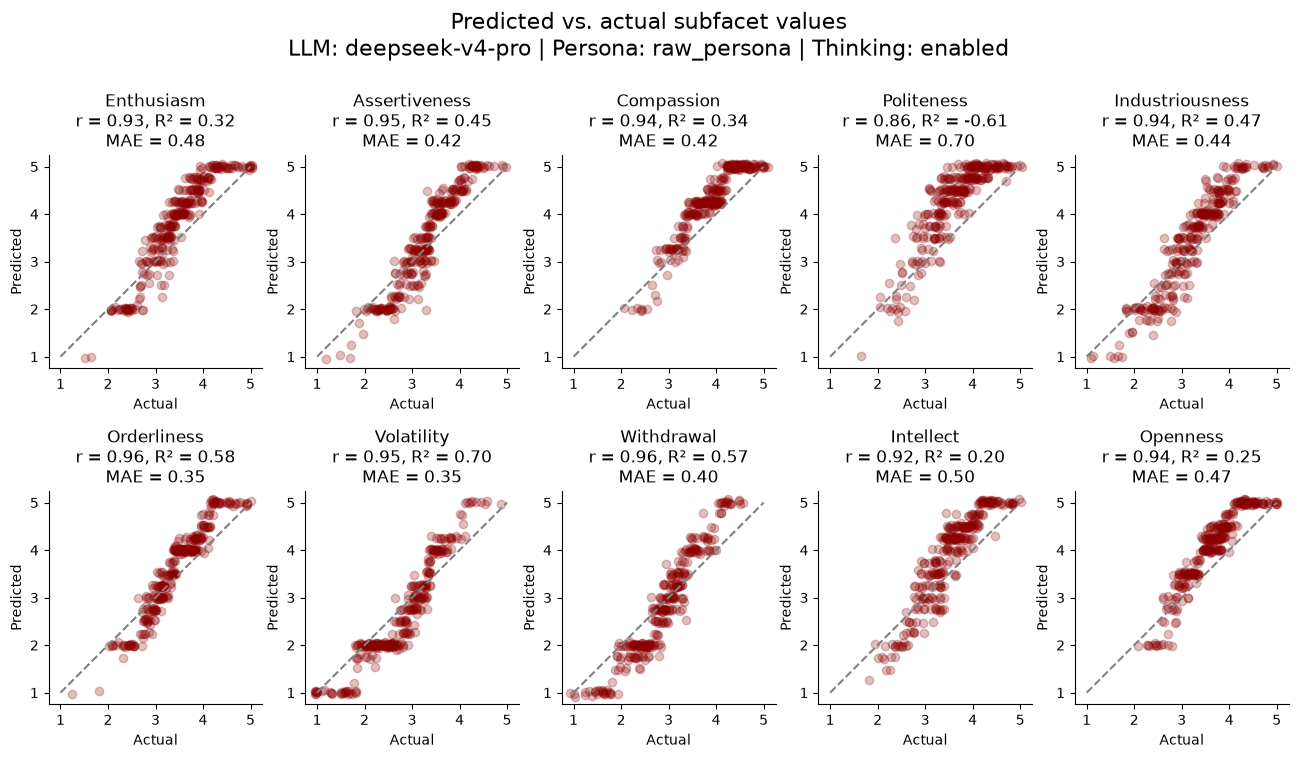

In [20]:
subfacets = get_traits("Subdomain")
rng = np.random.default_rng(42)
jitter_sd = 0.03
for (llm, persona, thinking), condition in df.groupby(["llm", "persona", "thinking"]):
    
    n_traits = len(subfacets)
    n_cols = 5
    n_rows = 2
    
    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(16, 4 * n_rows)
    )
    
    axes = np.asarray(axes).flatten()
    
    for ax, trait in zip(axes, subfacets):

        x_jitter = rng.normal(0, jitter_sd, len(condition))
        y_jitter = rng.normal(0, jitter_sd, len(condition))
        
        # Point-level data
        actual = condition[trait]
        predicted = condition[f"{trait}_evaluated"]


        # Get metrics from evaluation_df
        metrics = evaluation_df[
            (evaluation_df["llm"] == llm) &
            (evaluation_df["persona"] == persona) &
            (evaluation_df["thinking"] == thinking) &
            (evaluation_df["trait"] == trait)
        ].iloc[0]
        
        # Scatter plot
        ax.scatter(
            actual + x_jitter,
            predicted + y_jitter,
            alpha=0.25,
            c="darkred",
        )
        
        # Perfect prediction line
        ax.plot(
            [1, 5],
            [1, 5],
            linestyle="--",
            color="gray",
        )
        
        # Metrics
        ax.set_title(
            f"{trait}\n"
            f"r = {metrics['pearson_r']:.2f}, "
            f"R² = {metrics['R²']:.2f}\n"
            f"MAE = {metrics['MAE']:.2f}"
        )
        
        ax.set_xlabel("Actual")
        ax.set_ylabel("Predicted")
        ax.set_xlim(.75, 5.25)
        ax.set_ylim(.75, 5.25)
        
        ax.set_aspect("equal", adjustable="box")
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    # Remove unused axes
    for ax in axes[len(subfacets):]:
        ax.remove()
    
    fig.suptitle(
        f"Predicted vs. actual subfacet values\n"
        f"LLM: {llm} | Persona: {persona} | Thinking: {thinking}",
        fontsize=16,
        y=1.02
        )
    fig.savefig(f"plots/big_five_evaluation/big_five_evaluation_{llm}_{persona}_{thinking}.png", bbox_inches="tight")